# Controle

Este notebook analisa a controlabilidade do modelo linearizado e, em seguida, projeta um controlador para o sistema.

## Controlabilidade

Um sistema é controlável quando é possível levar seus estados de qualquer condição inicial a qualquer estado final, em tempo finito, por meio das entradas. Para o sistema $\dot{\mathbf{x}} = \mathbf{A}\,\mathbf{x} + \mathbf{B}\,\mathbf{u}$ com $n$ estados, o teste usa a matriz de controlabilidade:

$$\mathcal{C} = \begin{bmatrix} \mathbf{B} & \mathbf{A}\mathbf{B} & \mathbf{A}^2\mathbf{B} & \dots & \mathbf{A}^{n-1}\mathbf{B} \end{bmatrix}$$

O sistema é controlável se, e somente se, o posto de $\mathcal{C}$ é igual a $n$. Aqui $n = 9$ e há 3 entradas, então $\mathcal{C}$ tem dimensão $9 \times 27$.


In [1]:
import control
import hickle as hkl
import numpy as np

A = np.array(hkl.load("../outputs/A.hkl"), dtype=float)
B = np.array(hkl.load("../outputs/B.hkl"), dtype=float)

# Matriz de controlabilidade
Ctl = control.ctrb(A, B)

# Teste de controlabilidade
num_linhas = Ctl.shape[0]
posto = np.linalg.matrix_rank(Ctl)

msg = "Sistema controlável" if posto == num_linhas else "Sistema incontrolável"
print(f"Número de estados: {num_linhas}; Posto da matriz: {posto}; {msg}")


Número de estados: 9; Posto da matriz: 9; Sistema controlável


## Controle regulatório proporcional

O modelo linearizado em espaço de estados, o controle regulatório proporcional é uma realimentação de estados com um ganho $\mathbf{K} \in \mathbb{R}^{3 \times 9}$:

$$\mathbf{u}(t) = -\mathbf{K}\,\mathbf{x}(t)$$

O objetivo é regular o processo, isto é, levar os desvios $\mathbf{x}$ de volta a zero, o ponto de operação, após uma perturbação. Substituindo a lei de controle no modelo, o espaço de estados de malha fechada é

$$\dot{\mathbf{x}}(t) = (\mathbf{A} - \mathbf{B}\mathbf{K})\,\mathbf{x}(t)$$

e a dinâmica passa a ser determinada pelos autovalores de $\mathbf{A} - \mathbf{B}\mathbf{K}$. Para obter $\mathbf{K}$ usa-se a **alocação de polos**: escolhem-se os polos desejados de malha fechada e calcula-se o $\mathbf{K}$ que os coloca nessas posições, o que é possível porque o sistema é controlável.


In [2]:
import sympy as sp
from scipy.signal import place_poles

from lib.utils import show

# Polos em malha aberta, do mais rápido ao mais lento
lam = np.linalg.eigvals(A)
lam = lam[np.argsort(lam.real)]

polos_desejados = np.array([-60, -50, -40, -35, -30, -25, -23, -22, -20])

# Ganho K por alocação de polos
K = place_poles(A, B, polos_desejados).gain_matrix  # type: ignore

show(r"\mathbf{K}", sp.Matrix(K))
print("Polos em malha fechada:", np.sort_complex(np.linalg.eigvals(A - B @ K)).round(2))


/tmp/ipykernel_174457/3938315413.py:13: UserWarning: Convergence was not reached after maxiter iterations.
You asked for a tolerance of 0.001, we got 0.9998320790751096.
  K = place_poles(A, B, polos_desejados).gain_matrix  # type: ignore


<IPython.core.display.Math object>

Polos em malha fechada: [-60.+0.j -50.+0.j -40.+0.j -35.+0.j -30.+0.j -25.+0.j -23.+0.j -22.+0.j
 -20.+0.j]


Para testar o controlador, aplica-se uma perturbação no instante inicial: um aumento súbito na temperatura do reator 1 ($T_1$), com todos os outros estados no ponto de operação. A simulação mostra como o controle $\mathbf{u} = -\mathbf{K}\mathbf{x}$ leva o processo de volta ao setpoint, que é o ponto de operação (linha tracejada vermelha), e quais ações de controle ele usa para isso.


In [3]:
from lib.inputs import Ff1_func, Ff2_func, FR_func
from lib.parameters import y0
from lib.plots import plot_and_show, plt
from lib.utils import input_labels, input_units, output_units

x_ss = np.asarray(y0, dtype=float)  # setpoint dos estados
u0 = np.array([f(0.0) for f in (Ff1_func, Ff2_func, FR_func)])  # entradas nominais

# Perturbação: desvio inicial em T1
dx0 = np.array([5.0, 0, 0, 0, 0, 0, 0, 0, 0])

t = np.linspace(0, 1, 500)

# Malha fechada: x' = (A - BK) x, partindo do desvio inicial
sys_mf = control.StateSpace(A - B @ K, B, np.eye(len(A)), np.zeros_like(B))
x = control.initial_response(sys_mf, t, X0=dx0, return_x=True).states.T  # type: ignore
u = -x @ K.T  # (N, 3)

# Valores absolutos
x = x + x_ss
u = u + u0


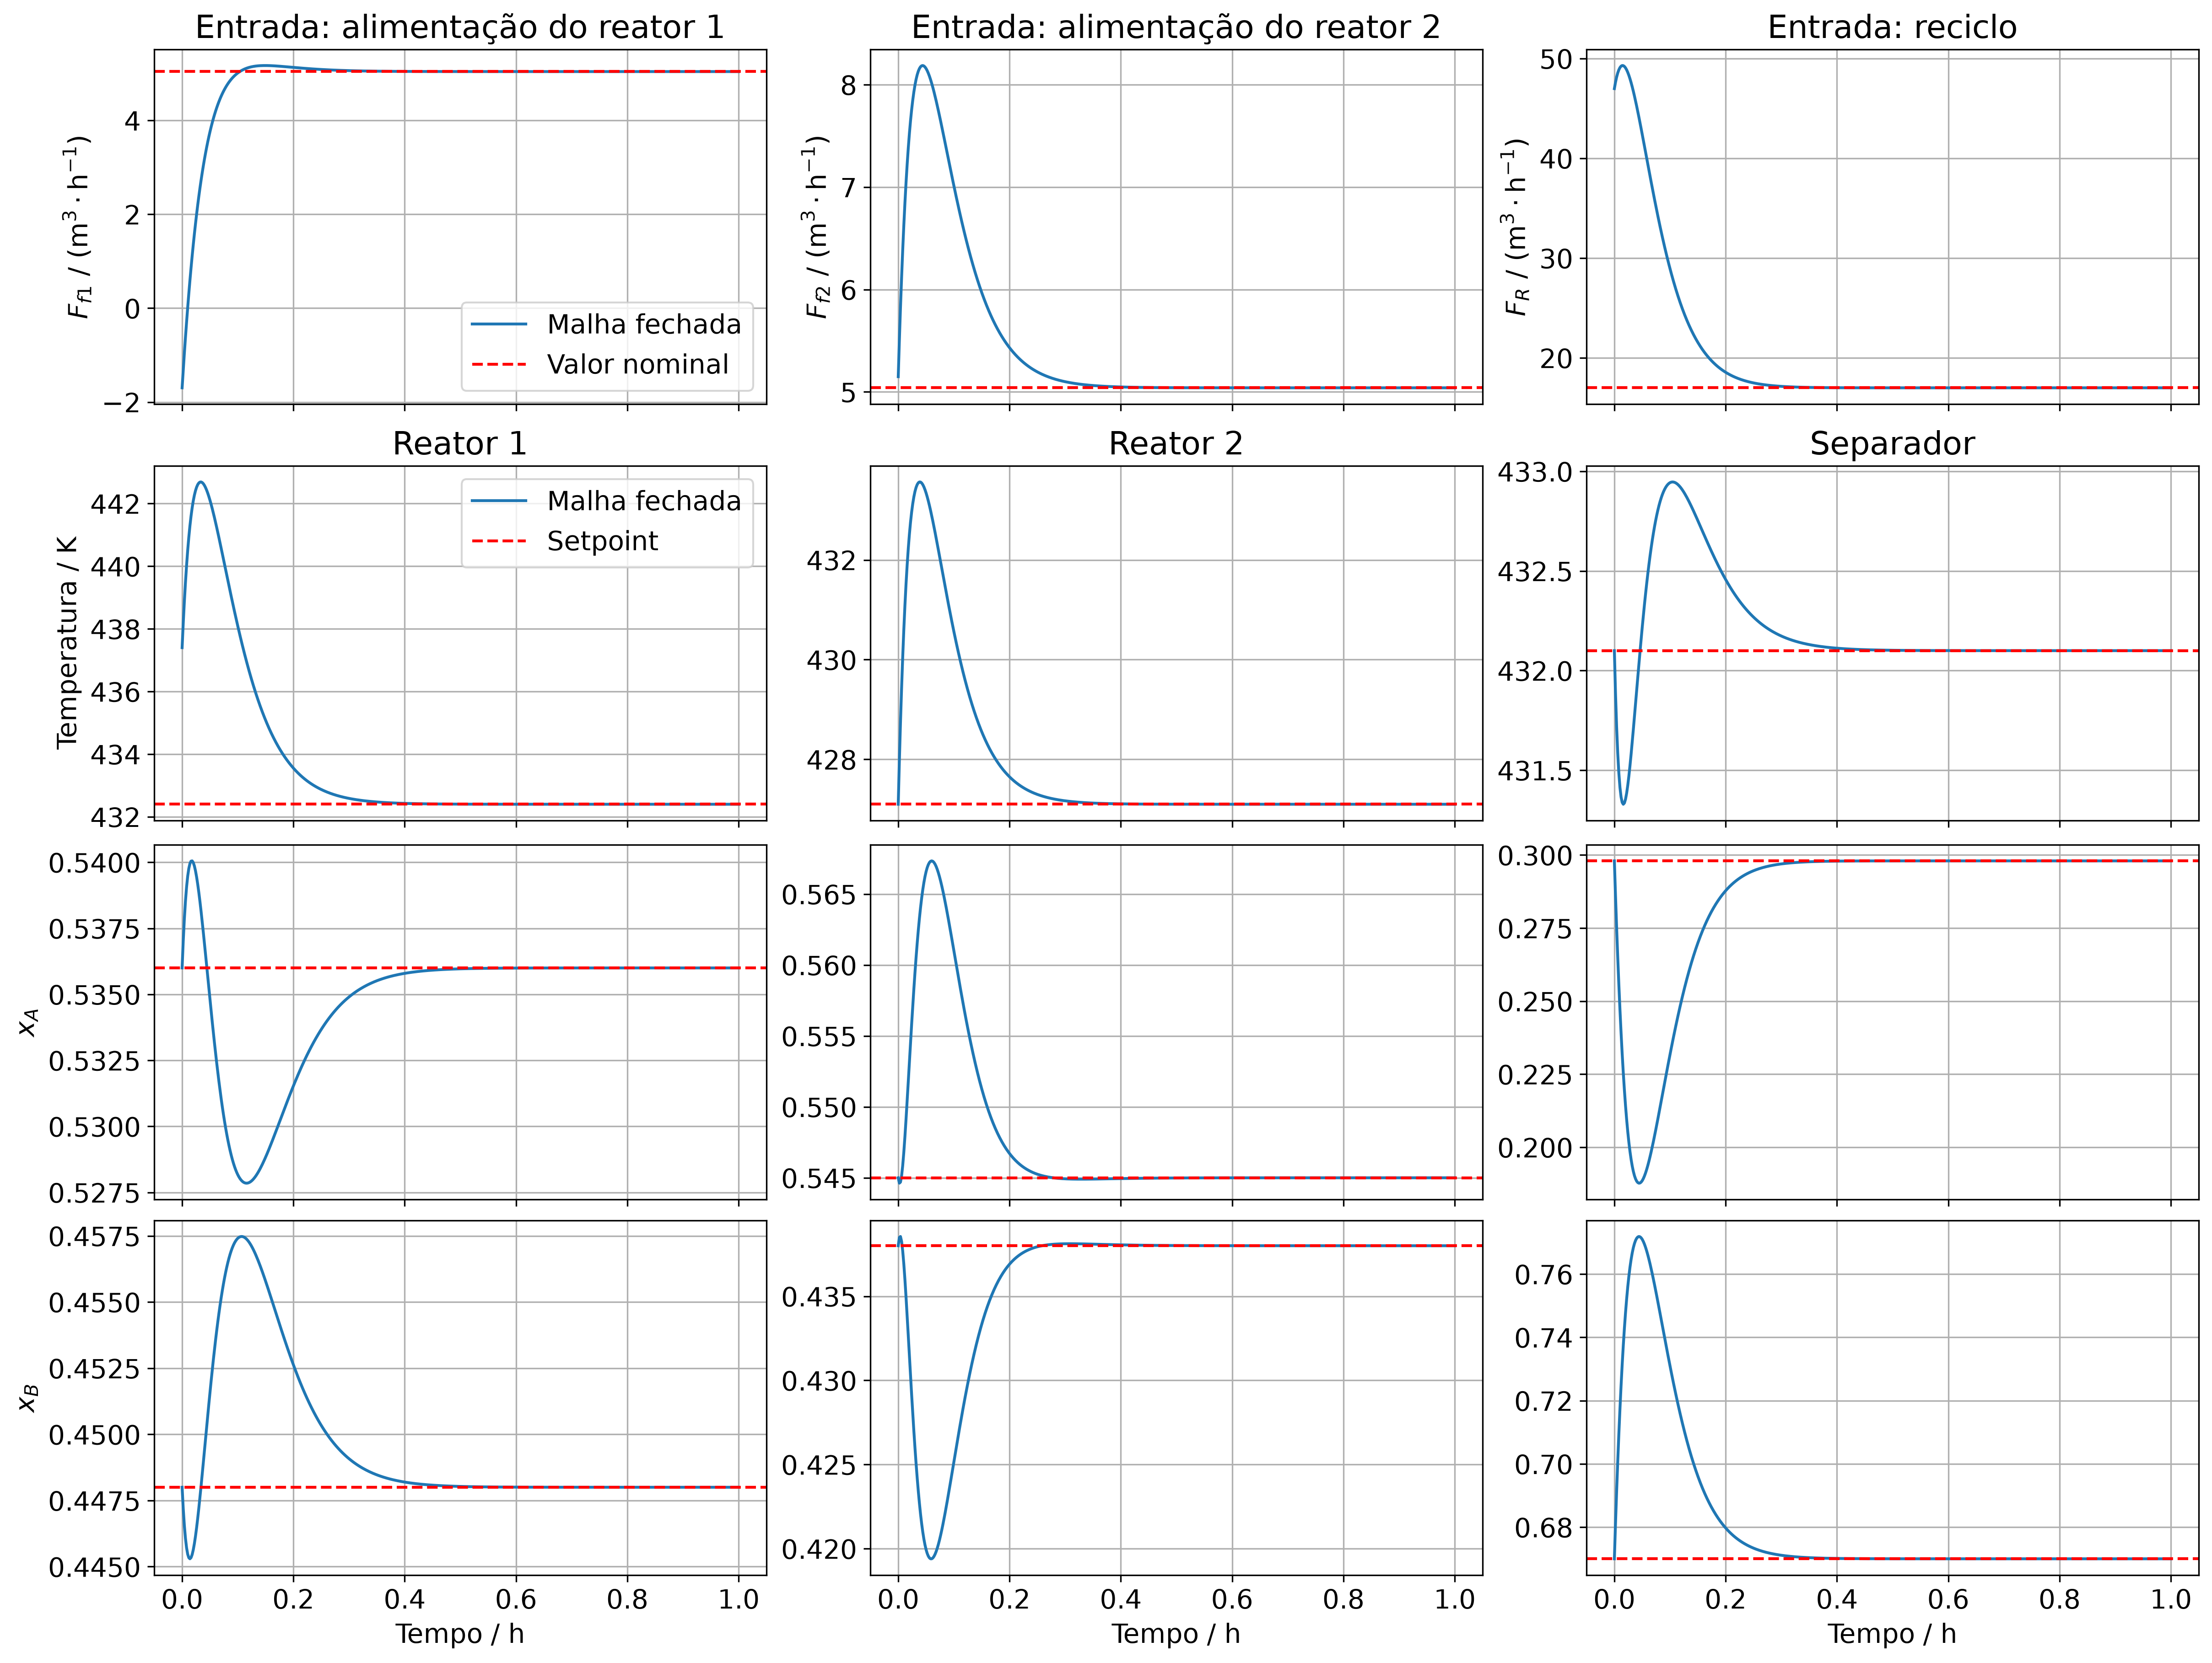

In [4]:
# Linha 1: entradas; linhas 2 a 4: estados (temperatura, xA, xB) por unidade
linhas = [
    (f"Temperatura / {output_units[0]}", [0, 1, 2]),
    ("$x_A$", [3, 5, 7]),
    ("$x_B$", [4, 6, 8]),
]
titulos = ["Reator 1", "Reator 2", "Separador"]
titulos_entradas = [
    "Entrada: alimentação do reator 1",
    "Entrada: alimentação do reator 2",
    "Entrada: reciclo",
]

fig, axs = plt.subplots(4, 3, figsize=(16, 12), sharex=True, constrained_layout=True)

for j in range(3):
    ax = axs[0, j]
    ax.plot(t, u[:, j], label="Malha fechada")
    ax.axhline(u0[j], color="r", ls="--", label="Valor nominal")
    ax.set_title(titulos_entradas[j])
    ax.set_ylabel(f"{input_labels[j]} / {input_units[j]}")
    ax.grid(True)

for r, (ylabel, estados) in enumerate(linhas, start=1):
    for c, e in enumerate(estados):
        ax = axs[r, c]
        ax.plot(t, x[:, e], label="Malha fechada")
        ax.axhline(x_ss[e], color="r", ls="--", label="Setpoint")

        if r == 1:
            ax.set_title(titulos[c])
        if c == 0:
            ax.set_ylabel(ylabel)
        if r == 3:
            ax.set_xlabel("Tempo / h")
        ax.grid(True)

axs[0, 0].legend()
axs[1, 0].legend()
plot_and_show("controle")
